# Gillespie SSA for SI and SIS Epidemic Models

This notebook implements the Gillespie stochastic simulation algorithm (SSA) for two compartmental models:

- **Case 1, SI:** $S + I \xrightarrow{\beta/N} 2I$
- **Case 2, SIS:** $S + I \xrightarrow{\beta/N} 2I$ and $I \xrightarrow{\gamma} S$

For each reaction channel $j$, the propensity is $a_j$. The time to the next event is $\tau = \frac{1}{a_0}\ln(1/r_1)$, where $a_0 = \sum_j a_j$. The channel is chosen as the smallest $j$ with $\sum_{k\le j} a_k \ge r_2 a_0$.

The ODE solutions from `solve_ivp` are shown alongside the stochastic trajectories as a check.

## Generic Gillespie SSA

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


def gillespie(x0, stoich, propensity, t_max, rng=None):
    """
    ====================================================================================
    x0         : initial state vector, e.g. [S_0, I_0]
    stoich     : array of shape (M, N_species); row j is the stoichiometry vector nu_j
    propensity : function x -> array of M propensities a_j(x)
    t_max      : final simulation time
    rng        : numpy Generator (optional)
    ====================================================================================
    Returns (times, states) recorded at each event.
    ====================================================================================
    """
    rng = np.random.default_rng() if rng is None else rng
    x = np.array(x0, dtype=int)
    t = 0.0
    times = [t]
    states = [x.copy()]

    while t < t_max:
        a = np.asarray(propensity(x), dtype=float)
        a0 = a.sum()
        if a0 <= 0:          # no reaction can occur (e.g. S = 0 or I = 0)
            break

        # Random numbers in (0, 1] to avoid log(0) and zero-threshold issues
        r1 = 1.0 - rng.random()
        r2 = 1.0 - rng.random()

        tau = np.log(1.0 / r1) / a0          # time step
        j = np.searchsorted(np.cumsum(a), r2 * a0)  # selected channel (0-indexed)
        t += tau
        if t > t_max:
            break

        x = x + stoich[j]
        times.append(t)
        states.append(x.copy())
    return np.array(times), np.array(states)


def resample(times, states, grid):
    idx = np.searchsorted(times, grid, side='right') - 1
    return states[idx]

## Case 1: SI model

**Reaction:** $S + I \xrightarrow{\beta/N} 2I$

**Stoichiometry:** $\nu_1 = (-1, +1)$

**Propensity:** $a_1 = \frac{\beta}{N} S I$

**ODEs:** $\dot S = -\frac{\beta}{N} S I$, $\dot I = \frac{\beta}{N} S I$

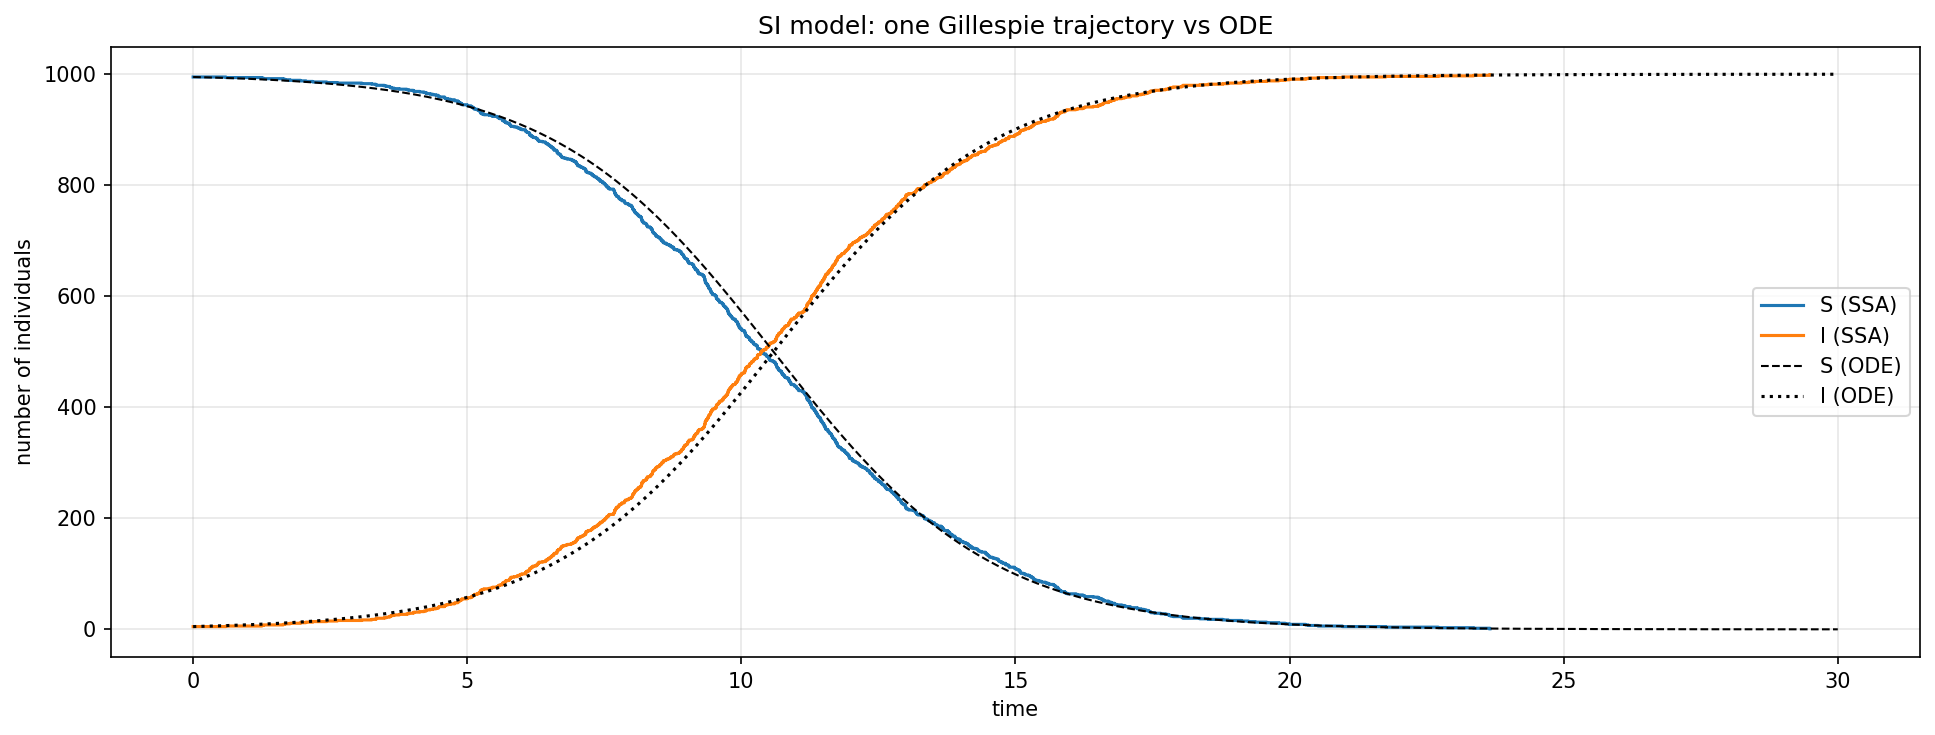

Number of events: 994
Final state: S = 1, I = 999


In [7]:
# Parameters
N = 1000          # total population (held constant)
beta = 0.5        # transmission rate
S0, I0 = N - 5, 5 # initial condition
T_max = 30.0

# SI model
stoich_SI = np.array([[-1, +1]])   # one channel: S -> S - 1, I -> I + 1

def propensity_SI(x):
    S, I = x
    return np.array([beta / N * S * I])

def ode_SI(t, y):
    S, I = y
    return [-beta / N * S * I, beta / N * S * I]

# One stochastic trajectory
rng = np.random.default_rng(42)
times, states = gillespie([S0, I0], stoich_SI, propensity_SI, T_max, rng)

# Deterministic reference
t_grid = np.linspace(0, T_max, 500)
sol = solve_ivp(ode_SI, (0, T_max), [S0, I0], t_eval=t_grid, rtol=1e-8, atol=1e-8)

fig, ax = plt.subplots(figsize=(13, 5), dpi=150)
ax.step(times, states[:, 0], where='post', label='S (SSA)')
ax.step(times, states[:, 1], where='post', label='I (SSA)')
ax.plot(sol.t, sol.y[0], 'k--', lw=1, label='S (ODE)')
ax.plot(sol.t, sol.y[1], 'k:', lw=1.5, label='I (ODE)')
ax.set_xlabel('time')
ax.set_ylabel('number of individuals')
ax.set_title('SI model: one Gillespie trajectory vs ODE')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Number of events: {len(times) - 1}')
print(f'Final state: S = {states[-1, 0]}, I = {states[-1, 1]}')

## Case 2: SIS model

**Reactions:**
- R1: $S + I \xrightarrow{\beta/N} 2I$, with $\nu_1 = (-1, +1)$ and $a_1 = \frac{\beta}{N} S I$
- R2: $I \xrightarrow{\gamma} S$, with $\nu_2 = (+1, -1)$ and $a_2 = \gamma I$

**ODEs:** $\dot I = I\left[\beta(1 - I/N) - \gamma\right]$, with endemic equilibrium $I^* = N(1 - \gamma/\beta)$ when $\beta > \gamma$.

In [8]:
# Parameters
N = 1000
beta = 0.5
gamma = 0.2
S0, I0 = N - 5, 5
T_max = 100.0
R0 = beta / gamma
I_star = N * (1 - gamma / beta)   # equilibrium (exists when R_0 > 1)

# SIS model definitions
stoich_SIS = np.array([
    [-1, +1],   # R1: infection, S -> S - 1, I -> I + 1
    [+1, -1],   # R2: recovery,  S -> S + 1, I -> I - 1
])

def propensity_SIS(x):
    S, I = x
    return np.array([beta / N * S * I, gamma * I])

def ode_SIS(t, y):
    S, I = y
    return [-beta / N * S * I + gamma * I, beta / N * S * I - gamma * I]

print(f'R0 = {R0:.2f},  predicted endemic equilibrium I* = {I_star:.1f}')

R0 = 2.50,  predicted endemic equilibrium I* = 600.0


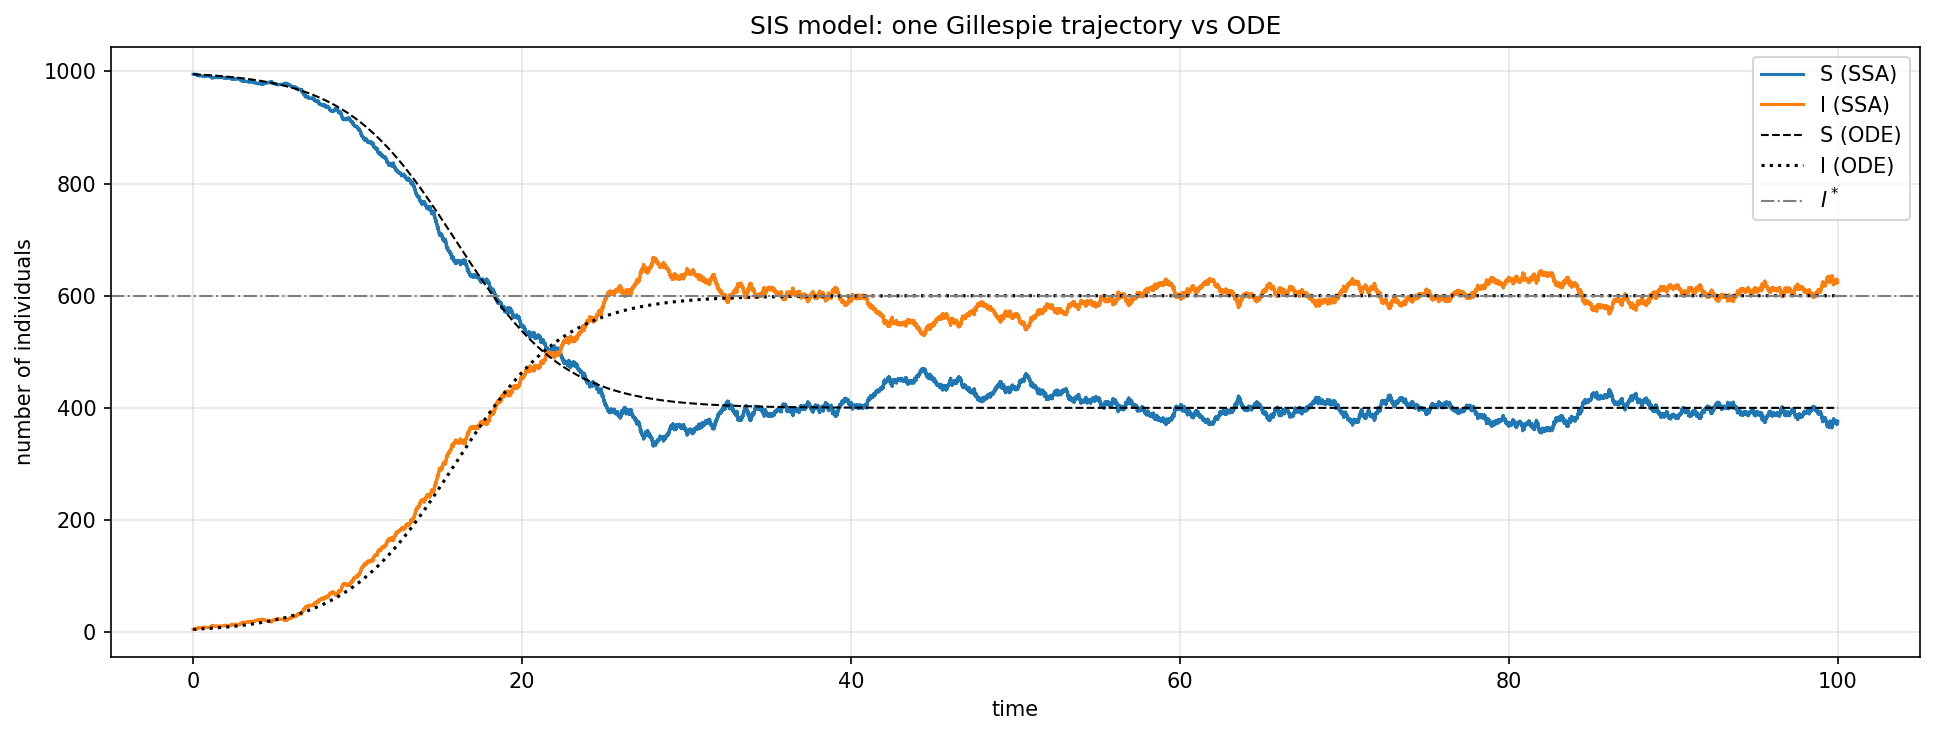

In [9]:
# Single SIS trajectory
rng = np.random.default_rng(1)
times, states = gillespie([S0, I0], stoich_SIS, propensity_SIS, T_max, rng)

t_grid = np.linspace(0, T_max, 500)
sol = solve_ivp(ode_SIS, (0, T_max), [S0, I0], t_eval=t_grid, rtol=1e-8, atol=1e-8)

fig, ax = plt.subplots(figsize=(13, 5), dpi=150)
ax.step(times, states[:, 0], where='post', label='S (SSA)')
ax.step(times, states[:, 1], where='post', label='I (SSA)')
ax.plot(sol.t, sol.y[0], 'k--', lw=1, label='S (ODE)')
ax.plot(sol.t, sol.y[1], 'k:', lw=1.5, label='I (ODE)')
ax.axhline(I_star, color='gray', ls='-.', lw=1, label=r'$I^*$')
ax.set_xlabel('time')
ax.set_ylabel('number of individuals')
ax.set_title('SIS model: one Gillespie trajectory vs ODE')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()